# Statistical Investigation of Factors Associated with Student Stress

## 1. Project Overview

### 1.1 Background

Student stress is a multifaceted phenomenon that may be associated with psychological well-being, physiological symptoms, environmental conditions, academic demands, and social experiences. Examining these dimensions can help identify patterns in student well-being and relationships that warrant further investigation.

Statistical analysis provides a systematic approach to describing these patterns, assessing the strength and direction of observed associations, and evaluating evidence relevant to research hypotheses.

### 1.2 Problem Statement

Understanding student stress requires examining factors beyond academic demands alone. This project investigates how selected psychological, physiological, environmental, academic, and social variables are associated with recorded stress-level categories in a student dataset.

Using descriptive statistics, exploratory data analysis, and statistical hypothesis testing, the study focuses on the strength and direction of associations and the interpretation of statistical evidence rather than on prediction alone.

### 1.3 Data Source

This project uses the publicly available Student Stress Factors: A Comprehensive Analysis dataset, `StressLevelDataset.csv`, described by de Filippis and Al Foysal (2024) in their study, *Comprehensive analysis of stress factors affecting students: a machine learning approach*. The dataset contains 1,100 records, 20 explanatory variables, and one outcome variable, `stress_level`.

The dataset is used for secondary statistical analysis. Its variable definitions, measurement scales, coding, and data provenance will be examined before conducting the main statistical tests.

### 1.4 Research Questions

The overarching research question guiding this investigation is:

How are selected psychological, physiological, environmental, academic, and social factors associated with recorded stress-level categories in the student dataset?

To address this question, the analysis will investigate the following specific research questions:

- **Psychological factors:** Are anxiety level and self-esteem associated with recorded stress levels?
- **Physiological factors:** Are sleep quality and the recorded blood-pressure variable associated with recorded stress levels?
- **Environmental factors:** Are selected environmental conditions, such as safety and basic needs, associated with recorded stress levels?
- **Academic factors:** Are academic performance and future career concerns associated with recorded stress levels?
- **Social factors:** Are bullying and social support associated with recorded stress levels?

These questions define the main areas of investigation and guide the selection of variables and statistical methods.

### 1.5 Research Objectives

The objectives of this project are to:

- Describe the distribution and characteristics of the variables in the student stress dataset using descriptive statistics and exploratory data analysis.
- Assess the strength and direction of associations between selected explanatory variables and recorded stress levels.
- Formulate and test appropriate statistical hypotheses based on the research questions.
- Report and interpret statistical evidence using suitable test statistics, p-values, effect sizes, and confidence intervals where appropriate.
- Investigate potential data-quality and coding concerns that may affect the interpretation of the results.
- Discuss the statistical findings, methodological limitations, and implications of the analysis without making unsupported causal claims.

### 1.6 Scope and Limitations

This investigation is limited to the variables available in the dataset and the information that can be verified about their definitions and measurement. Recorded stress levels will be treated as dataset-defined categories rather than independently validated clinical diagnoses.

The analysis will focus on statistical associations rather than causal relationships. The interpretation and generalizability of the findings depend on the dataset's quality, variable coding, and the adequacy of its sampling and data-collection procedures.

The meanings of the numerical codes assigned to some variables and the method used to generate the recorded stress-level categories are not fully documented in the available study information. These limitations will be considered when interpreting the results.

## 2. Data Loading and Initial Inspection

In [1]:
# Import libraries
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the dataset
kaggle_path = Path("/kaggle/input/datasets/izedikeanita/"
                   "stressleveldataset-csv/StressLevelDataset.csv")
local_path = Path("StressLevelDataset.csv")

if kaggle_path.exists():
    data_path = kaggle_path
elif local_path.exists():
    data_path = local_path
else:
    raise FileNotFoundError("StressLevelDataset.csv was not found. "
                            "Place it beside this notebook or update the dataset path.")

# Load the dataset
df = pd.read_csv(data_path)

# Inspect the dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (1100, 21)

Column names:
['anxiety_level', 'self_esteem', 'mental_health_history', 'depression', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying', 'stress_level']


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


### Interpretation

The dataset contains 1,100 observations and 21 columns, comprising 20 explanatory variables and one outcome variable, `stress_level`. The variables cover psychological, physiological, environmental, academic, and social aspects of student life.

The first five records provide an initial view of the dataset's structure and recorded values. This inspection establishes the dataset's dimensions and column names, while subsequent checks examine data quality, variable ranges, and coding.

### 2.1 Data Quality Assessment

In [2]:
# Inspect data types
print("Data types:")
display(df.dtypes.to_frame(name="Data Type"))

# Check missing values
print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

Data types:


,Data Type
anxiety_level,int64
self_esteem,int64
mental_health_history,int64
depression,int64
headache,int64
blood_pressure,int64
sleep_quality,int64
breathing_problem,int64
noise_level,int64
living_conditions,int64



Missing values per column:


,Missing Values
anxiety_level,0
self_esteem,0
mental_health_history,0
depression,0
headache,0
blood_pressure,0
sleep_quality,0
breathing_problem,0
noise_level,0
living_conditions,0



Number of duplicate rows: 0


### Interpretation

The data quality assessment found no missing values across the 21 columns and no exact duplicate rows among the 1,100 observations.

All variables are stored as integers (`int64`). However, the storage format does not establish their measurement level. Some variables may represent categories or ordinal ratings, so their definitions and coding should be considered when selecting statistical methods.

### 2.2 Variable Range and Coding Inspection

In [3]:
# Inspect the number of unique values in each variable
print("Unique values per column:")
display(df.nunique().to_frame(name="Unique Values"))

# Inspect the minimum and maximum values
print("\nMinimum and maximum values:")
display(df.agg(["min", "max"]).T.rename(
        columns={"min": "Minimum", "max": "Maximum"}))

# Inspect the distinct stress-level categories
print("\nStress-level categories:")
print(sorted(df["stress_level"].unique()))

Unique values per column:


,Unique Values
anxiety_level,22
self_esteem,31
mental_health_history,2
depression,28
headache,6
blood_pressure,3
sleep_quality,6
breathing_problem,6
noise_level,6
living_conditions,6



Minimum and maximum values:


,Minimum,Maximum
anxiety_level,0,21
self_esteem,0,30
mental_health_history,0,1
depression,0,27
headache,0,5
blood_pressure,1,3
sleep_quality,0,5
breathing_problem,0,5
noise_level,0,5
living_conditions,0,5



Stress-level categories:
[np.int64(0), np.int64(1), np.int64(2)]


### Interpretation

The variables have different observed ranges. `anxiety_level` ranges from 0 to 21, `self_esteem` from 0 to 30, and `depression` from 0 to 27. Most of the remaining variables range from 0 to 5. `mental_health_history` has two observed values (0 and 1), `blood_pressure` has three (1–3), and `social_support` has four (0–3). The `stress_level` outcome contains three recorded categories: 0, 1, and 2.

These ranges describe the recorded values but do not establish what each code means or whether a variable is nominal, ordinal, or continuous. Variable interpretations should therefore be based on the available dataset documentation rather than assumptions about the numerical values.

### 2.3 Check the Distribution of the Outcome Variable

In [4]:
# Count observations in each stress category
stress_counts = df["stress_level"].value_counts().sort_index()

print("Stress-level counts:")
display(stress_counts.to_frame(name="Count"))

# Calculate percentages
stress_percentages = (df["stress_level"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Stress-level percentages:")
display(stress_percentages.to_frame(name="Percentage"))

Stress-level counts:


,Count
stress_level,
0,373
1,358
2,369


Stress-level percentages:


,Percentage
stress_level,
0,33.91
1,32.55
2,33.55


### Interpretation

The dataset contains 373 observations (33.91%) in stress category 0, 358 (32.55%) in category 1, and 369 (33.55%) in category 2. The proportions are relatively similar across the three categories, with no category substantially overrepresented. This indicates that the outcome variable is approximately balanced in terms of category counts.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of Stress-Level Categories

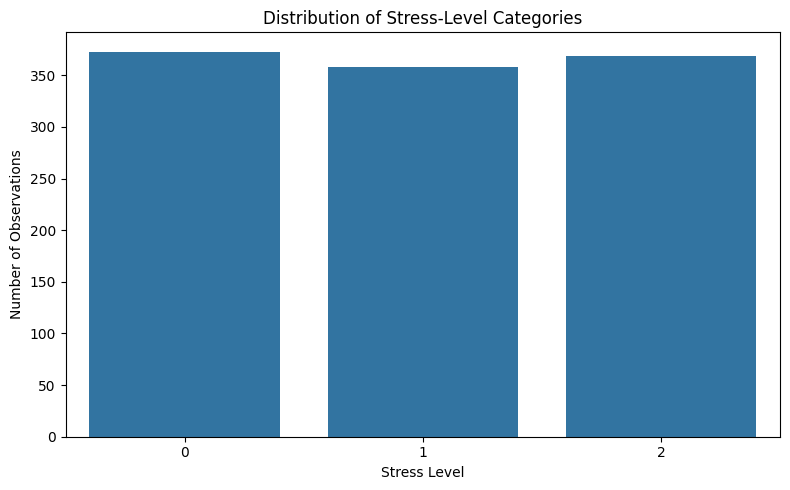

In [5]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate category counts
stress_counts = df["stress_level"].value_counts().sort_index()

# Plot the distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=stress_counts.index, y=stress_counts.values)

plt.title("Distribution of Stress-Level Categories")
plt.xlabel("Stress Level")
plt.ylabel("Number of Observations")
plt.xticks([0, 1, 2])
plt.tight_layout()
plt.show()

### Interpretation

The bar chart visually confirms the relatively even distribution of observations across the three recorded stress categories. No category substantially dominates the dataset.

### 3.2 Exploring the Distributions of Selected Psychological Variables

In [6]:
# Inspect the distributions of selected psychological variables
psychological_vars = ["anxiety_level","self_esteem","mental_health_history","depression"]

for column in psychological_vars:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().sort_index().to_frame(name="Count"))


Distribution of anxiety_level:


,Count
anxiety_level,
0,29
1,46
2,46
3,48
4,33
5,40
6,52
7,51
8,44



Distribution of self_esteem:


,Count
self_esteem,
0,24
1,28
2,21
3,25
4,19
5,19
6,31
7,28
8,26



Distribution of mental_health_history:


,Count
mental_health_history,
0,558
1,542



Distribution of depression:


,Count
depression,
0,44
1,36
2,36
3,47
4,35
5,43
6,36
7,42
8,49


### Interpretation

The frequency distributions show that the four psychological variables have different numerical ranges. `anxiety_level` ranges from 0 to 21, `self_esteem` from 0 to 30, and `depression` from 0 to 27. The most frequent values are 13 for anxiety (67 observations), 25 for self-esteem (83 observations), and 10 for depression (66 observations).The `mental_health_history` variable is nearly evenly distributed, with 558 observations coded as 0 and 542 coded as 1.

These results describe the frequency distributions of the recorded psychological variables. They do not, by themselves, establish the direction or strength of each variable's association with stress.

### 3.3 Exploring the Distributions of Selected Physiological Variables

In [7]:
# Inspect the distributions of selected physiological variables
physiological_vars = ["headache","blood_pressure","sleep_quality","breathing_problem"]

for column in physiological_vars:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().sort_index().to_frame(name="Count"))


Distribution of headache:


,Count
headache,
0,32
1,331
2,181
3,287
4,140
5,129



Distribution of blood_pressure:


,Count
blood_pressure,
1,300
2,300
3,500



Distribution of sleep_quality:


,Count
sleep_quality,
0,34
1,328
2,188
3,170
4,188
5,192



Distribution of breathing_problem:


,Count
breathing_problem,
0,43
1,179
2,325
3,139
4,287
5,127


### Interpretation

Among the physiological variables, headache code 1 was the most frequent (331 observations), while code 0 was the least frequent (32 observations). For `blood_pressure`, code 3 appeared 500 times, compared with 300 observations each for codes 1 and 2. For `sleep_quality`, code 1 was the most frequent (328 observations) and code 0 the least frequent (34 observations). For `breathing_problem`, code 2 was the most frequent (325 observations), followed by code 4 (287 observations).

These frequencies describe the recorded distributions but do not establish relationships with stress_level.The meanings of the numerical codes should not be inferred without supporting documentation. 

### 3.4: Exploring the Distributions of Selected Environmental Variables.

In [8]:
# Inspect the distributions of selected environmental variables
environmental_vars = ["noise_level","living_conditions","safety","basic_needs"]

for column in environmental_vars:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().sort_index().to_frame(name="Count"))


Distribution of noise_level:


,Count
noise_level,
0,36
1,188
2,313
3,289
4,137
5,137



Distribution of living_conditions:


,Count
living_conditions,
0,29
1,176
2,346
3,327
4,189
5,33



Distribution of safety:


,Count
safety,
0,33
1,184
2,348
3,180
4,184
5,171



Distribution of basic_needs:


,Count
basic_needs,
0,40
1,173
2,335
3,190
4,173
5,189


### Interpretation

The frequency distributions show variation across the four environmental variables. For `noise_level`, value 2 occurs most frequently (313 observations). For `living_conditions`, value 2 is the most common (346 observations), closely followed by value 3 (327). Similarly, value 2 is the most frequent for both `safety` (348 observations) and `basic_needs` (335 observations).

These results indicate that values 2 and 3 account for many observations across the environmental variables. However, the numerical categories should not be interpreted as better or worse conditions until their coding is verified. These distributions describe the recorded values but do not establish relationships with `stress_level`.

### 3.5 Exploring the Distributions of Selected Academic Variables

In [9]:
# Inspect the distributions of selected academic variables
academic_vars = ["academic_performance","study_load","teacher_student_relationship","future_career_concerns"]

for column in academic_vars:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().sort_index().to_frame(name="Count"))


Distribution of academic_performance:


,Count
academic_performance,
0,28
1,185
2,348
3,169
4,188
5,182



Distribution of study_load:


,Count
study_load,
0,37
1,185
2,333
3,275
4,142
5,128



Distribution of teacher_student_relationship:


,Count
teacher_student_relationship,
0,42
1,190
2,353
3,183
4,192
5,140



Distribution of future_career_concerns:


,Count
future_career_concerns,
0,30
1,327
2,199
3,173
4,185
5,186


### Interpretation

The frequency distributions show variation across the four academic variables. Value 2 is the most frequent for `academic_performance` (348 observations), `study_load` (333 observations), and `teacher_student_relationship` (353 observations). For `future_career_concerns`, value 1 occurs most frequently, with 327 observations.

These results show that certain recorded values occur more frequently than others across the academic variables. However, the meaning and direction of each scale should be verified before interpreting the values. These distributions describe the variables but do not establish associations with `stress_level`.

### 3.6 Exploring the Distributions of Selected Social Variables

In [10]:
# Inspect the distributions of selected social variables
social_vars = ["social_support","peer_pressure","extracurricular_activities","bullying"]

for column in social_vars:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().sort_index().to_frame(name="Count"))


Distribution of social_support:


,Count
social_support,
0,88
1,412
2,142
3,458



Distribution of peer_pressure:


,Count
peer_pressure,
0,37
1,181
2,355
3,172
4,174
5,181



Distribution of extracurricular_activities:


,Count
extracurricular_activities,
0,34
1,184
2,332
3,178
4,198
5,174



Distribution of bullying:


,Count
bullying,
0,39
1,335
2,167
3,199
4,187
5,173


### Interpretation

The frequency distributions vary across the four social variables. For `social_support`, value 3 is the most frequent (458 observations), followed by value 1 (412 observations). For `peer_pressure`, value 2 occurs most frequently (355 observations). Similarly, value 2 is the most frequent for `extracurricular_activities` (332 observations), while value 1 is the most frequent for `bullying` (335 observations).

These results show that certain coded values occur more frequently than others. However, the meaning and direction of the scales must be verified before interpreting the values. The frequency distributions describe the recorded data but do not establish relationships with `stress_level`.

### 3.7 Summary Statistics of Numerical Variables

In [11]:
# Generate summary statistics for all variables
summary_stats = df.describe().T

display(summary_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
anxiety_level,1100.0,11.06,6.12,0.0,6.0,11.0,16.0,21.0
self_esteem,1100.0,17.78,8.94,0.0,11.0,19.0,26.0,30.0
mental_health_history,1100.0,0.49,0.50,0.0,0.0,0.0,1.0,1.0
depression,1100.0,12.56,7.73,0.0,6.0,12.0,19.0,27.0
headache,1100.0,2.51,1.41,0.0,1.0,3.0,3.0,5.0
blood_pressure,1100.0,2.18,0.83,1.0,1.0,2.0,3.0,3.0
sleep_quality,1100.0,2.66,1.55,0.0,1.0,2.5,4.0,5.0
breathing_problem,1100.0,2.75,1.40,0.0,2.0,3.0,4.0,5.0
noise_level,1100.0,2.65,1.33,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.52,1.12,0.0,2.0,2.0,3.0,5.0


### Interpretation

The summary statistics show that all 1,100 observations have recorded values across the 21 variables, consistent with the earlier missing-value assessment. The `anxiety_level`, `self_esteem`, and `depression` variables have wider numerical ranges than most of the other explanatory variables.

The `stress_level` variable ranges from 0 to 2, with a mean of 1.00 and a standard deviation of 0.82. Most other explanatory variables have observed values between 0 and 5, while `mental_health_history` is binary and `social_support` ranges from 0 to 3.

These statistics provide an overview of the variables' central values and variability. However, because several variables may be ordinal or categorical, their means and standard deviations should be interpreted cautiously until their coding and measurement scales are verified.

### 3.8 Visualisation of Explanatory Variables Against Stress Level

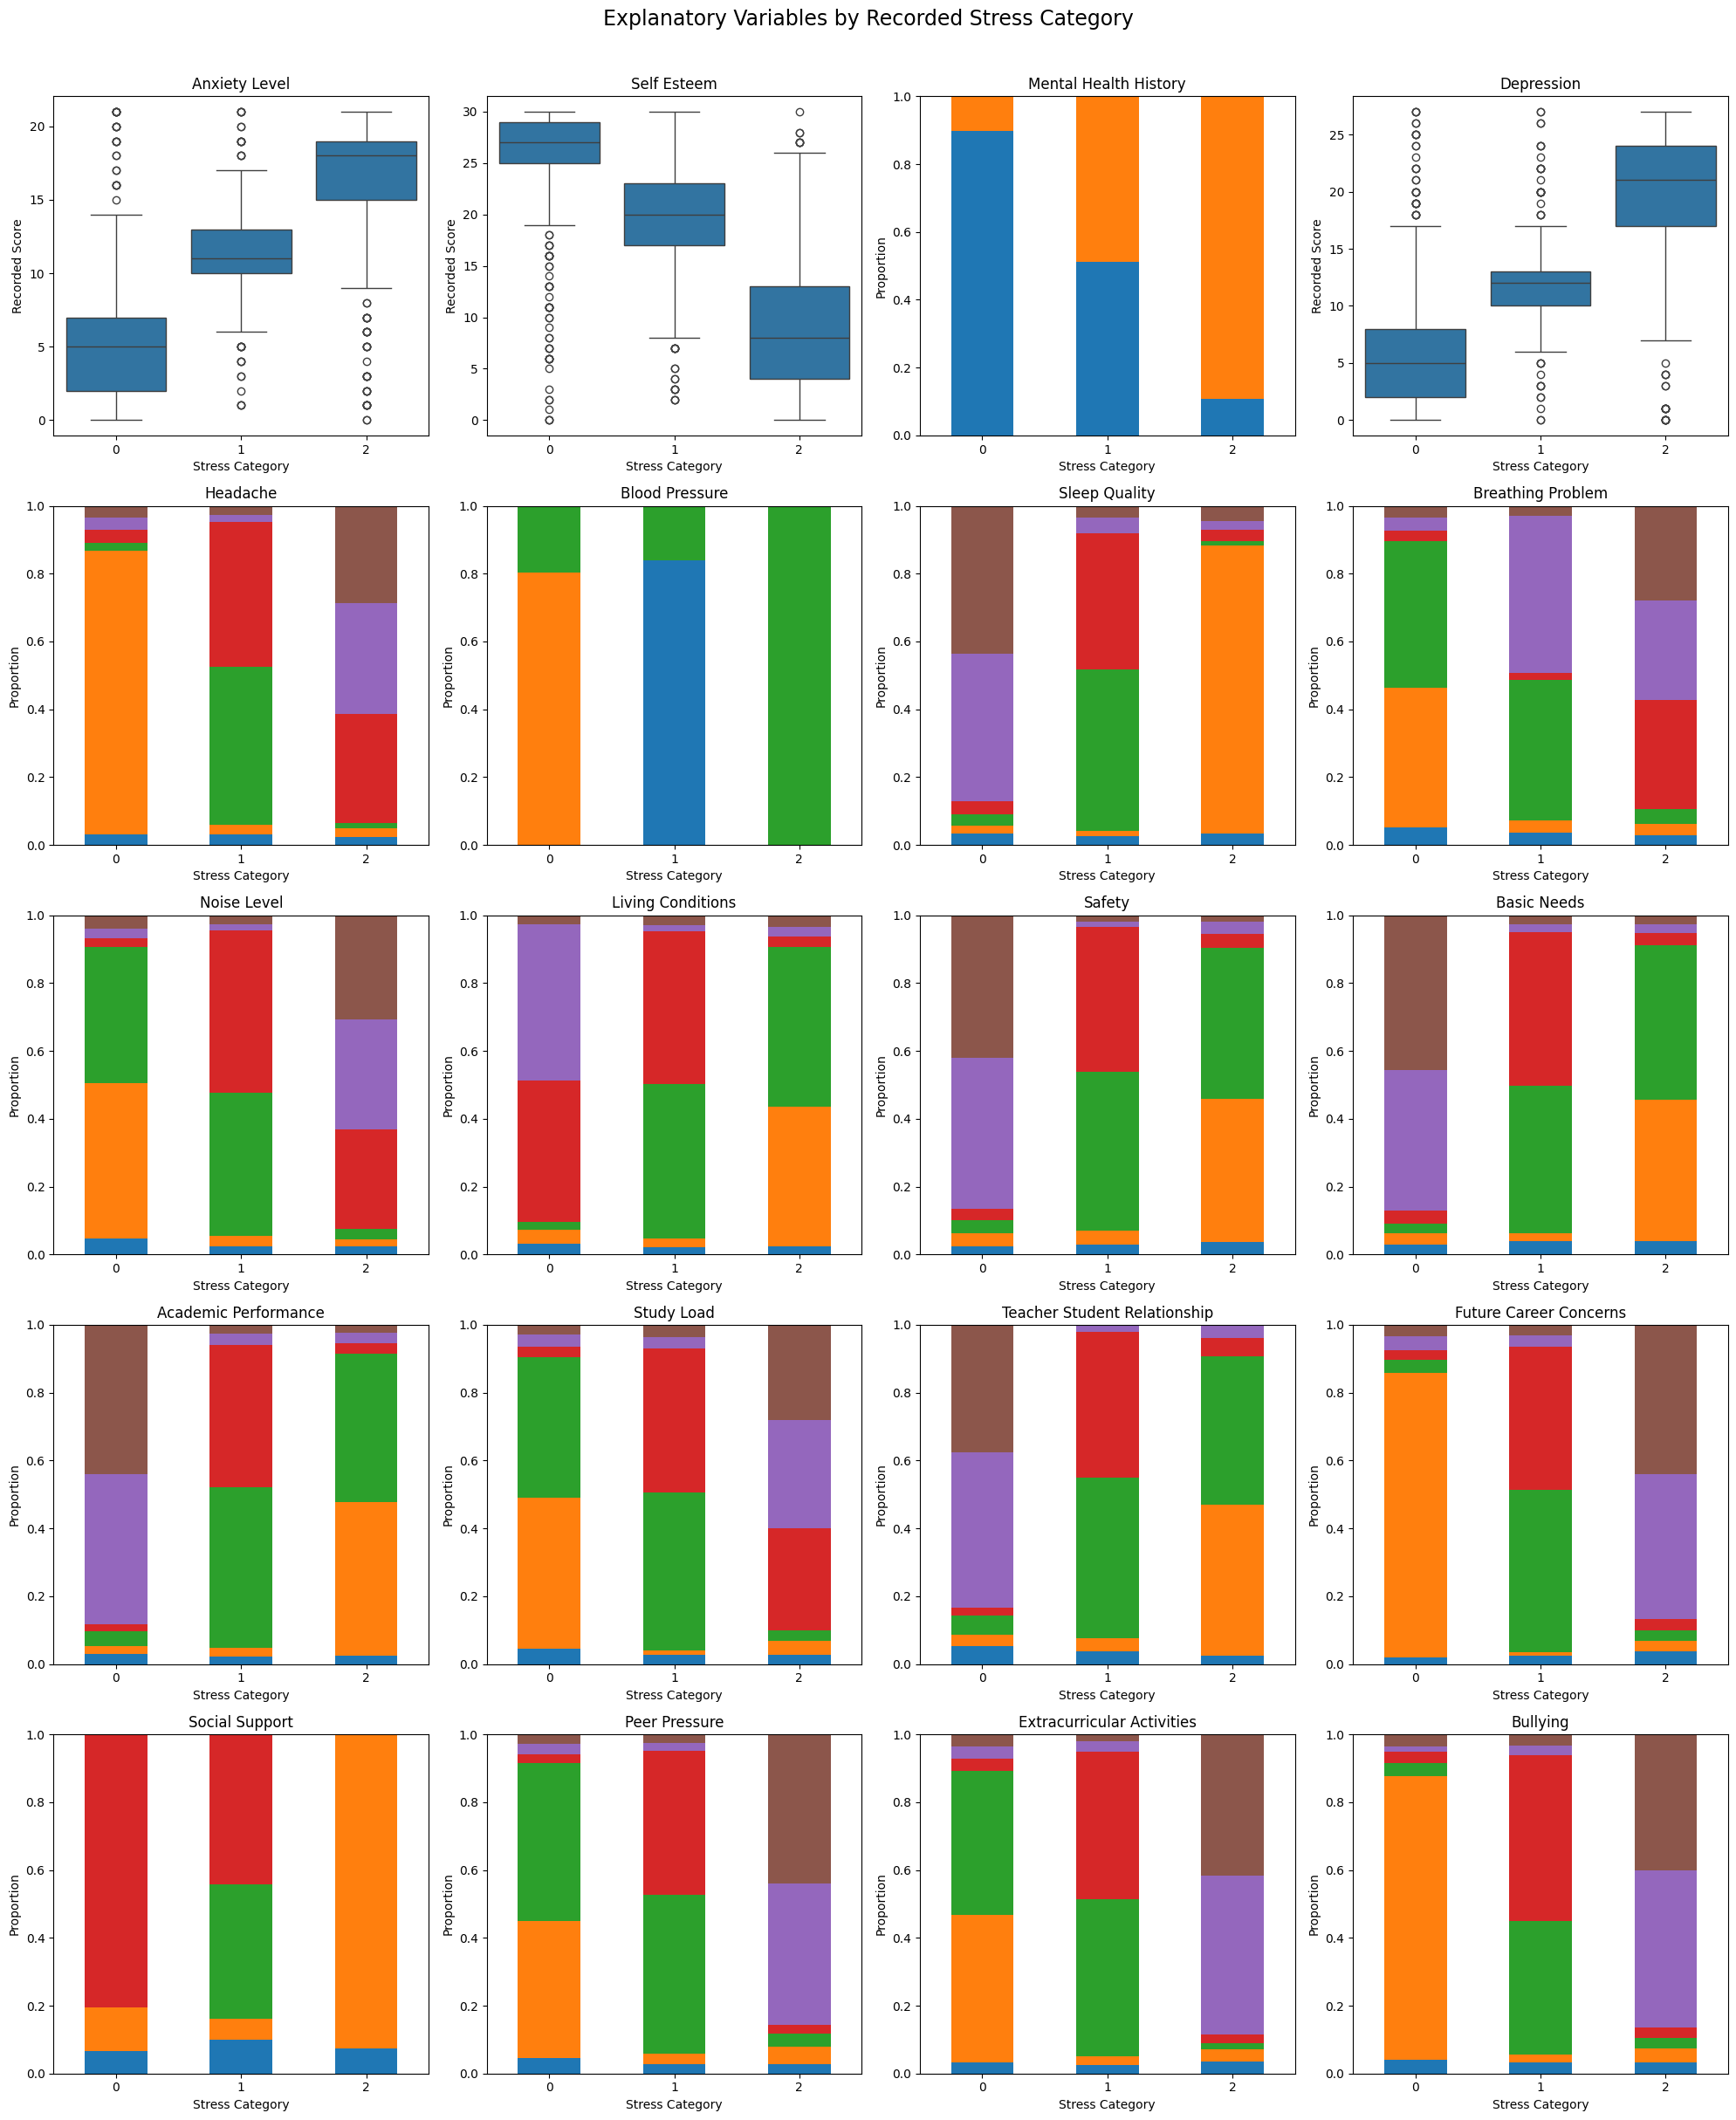

In [12]:
# Group explanatory variables by domain
variable_groups = {
    "Psychological": ["anxiety_level", "self_esteem","mental_health_history", "depression"],
    "Physiological": ["headache", "blood_pressure","sleep_quality", "breathing_problem"],
    "Environmental": ["noise_level", "living_conditions","safety", "basic_needs"],
    "Academic": ["academic_performance", "study_load","teacher_student_relationship", "future_career_concerns"],
    "Social": ["social_support", "peer_pressure","extracurricular_activities", "bullying"]
}

# Variables best explored initially with boxplots
boxplot_vars = ["anxiety_level","self_esteem","depression"]

# All explanatory variables
all_variables = [
    variable
    for variables in variable_groups.values()
    for variable in variables
]

# Create a 5-by-4 grid of plots
fig, axes = plt.subplots(5, 4, figsize=(20, 24))
axes = axes.flatten()

for ax, column in zip(axes, all_variables):

    if column in boxplot_vars:
        # Compare numerical score distributions across stress categories
        sns.boxplot(
            data=df,
            x="stress_level",
            y=column,
            ax=ax
        )
        ax.set_ylabel("Recorded Score")

    else:
        # Compare category proportions across stress categories
        proportions = pd.crosstab(
            df["stress_level"],
            df[column],
            normalize="index"
        )

        proportions.plot(
            kind="bar",
            stacked=True,
            ax=ax,
            legend=False
        )
        ax.set_ylabel("Proportion")
        ax.set_ylim(0, 1)
        ax.set_xlabel("Stress Category")
        ax.tick_params(axis="x", rotation=0)

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Stress Category")

plt.suptitle("Explanatory Variables by Recorded Stress Category",fontsize=17,y=1.01)

plt.tight_layout()
plt.show()


### Interpretation of Visualisations

The boxplots suggest differences in the distributions of anxiety, self-esteem, and depression scores across the recorded stress categories. Anxiety and depression appear to increase across categories, while self-esteem appears to decrease. These patterns suggest potential associations that should be examined using appropriate statistical tests.

The stacked bar charts also suggest that the distributions of several psychological, physiological, environmental, academic, and social variables vary across stress categories. These include mental health history, headache, blood pressure, study load, academic performance, social support, and bullying.

However, the visualisations alone cannot establish statistical significance, causation, or predictive importance. The meanings and direction of the coded values must also be verified before interpreting them as favourable or unfavourable conditions. Any apparent correspondence between a variable and stress category should be investigated further using appropriate statistical tests and effect sizes.

## 4. Statistical Association Analysis

### 4.1 Research Hypotheses

Based on the research questions established in Section 1.4, this section formulates statistical hypotheses to investigate associations between selected psychological, physiological, environmental, academic, and social factors and recorded student stress levels.

The hypotheses will be evaluated using two-sided Spearman rank correlation tests. For individual variables, the null hypothesis states that there is no monotonic association with recorded stress level, while the alternative hypothesis states that a monotonic association exists.

**Hypothesis 1: Psychological Factors**

- **H₀:** Neither anxiety level nor self-esteem has a monotonic association with recorded stress level.
- **H₁:** At least one of these psychological variables has a monotonic association with recorded stress level.

**Hypothesis 2: Physiological Factors**

- **H₀:** Neither sleep quality nor the recorded blood-pressure variable has a monotonic association with recorded stress level.
- **H₁:** At least one of these physiological variables has a monotonic association with recorded stress level.

The meanings of the blood-pressure codes have not been verified, so any association involving this variable will be interpreted cautiously.

**Hypothesis 3: Environmental Factors**

- **H₀:** Neither safety nor basic needs has a monotonic association with recorded stress level.
- **H₁:** At least one of these environmental variables has a monotonic association with recorded stress level.

**Hypothesis 4: Academic Factors**

- **H₀:** Neither academic performance nor future career concerns has a monotonic association with recorded stress level.
- **H₁:** At least one of these academic variables has a monotonic association with recorded stress level.

**Hypothesis 5: Social Factors**

- **H₀:** Neither bullying nor social support has a monotonic association with recorded stress level.
- **H₁:** At least one of these social variables has a monotonic association with recorded stress level.

The significance level will be set at 0.05. The Benjamini–Hochberg procedure will be used to adjust for multiple comparisons. Statistical significance will be interpreted alongside correlation strength, variable coding, and dataset limitations. Associations will not be interpreted as evidence of causation.


### 4.2 Statistical Hypothesis Testing Using Spearman Correlation Analysis

In [13]:
# Statistical Hypothesis Testing Using Spearman Correlation Analysis

# Import libraries
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Group variables according to the five research-question categories
factor_groups = {
    "Psychological Factors": ["anxiety_level", "self_esteem"],
    "Physiological Factors": ["sleep_quality", "blood_pressure"],
    "Environmental Factors": ["safety", "basic_needs"],
    "Academic Factors": ["academic_performance", "future_career_concerns"],
    "Social Factors": ["bullying", "social_support"]
}

# Calculate Spearman correlations for all selected variables
selected_variables = [
    variable
    for variables in factor_groups.values()
    for variable in variables
]

results = []

for variable in selected_variables:
    rho, p_value = spearmanr(df[variable], df["stress_level"])

    results.append({
        "Variable": variable,
        "Spearman Correlation (rho)": rho,
        "P-value": p_value
    })

# Adjust p-values for multiple testing using Benjamini-Hochberg
results_df = pd.DataFrame(results)

results_df["Adjusted P-value"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

# Organize results into the five research-question categories
grouped_results = []

for group, variables in factor_groups.items():
    for variable in variables:
        row = results_df.loc[
            results_df["Variable"] == variable
        ].iloc[0]

        grouped_results.append({
            "Factor Group": group,
            "Variable": variable,
            "Spearman Correlation (rho)": row["Spearman Correlation (rho)"],
            "Adjusted P-value": row["Adjusted P-value"],
            "Decision at 0.05": (
                "Reject individual H0"
                if row["Adjusted P-value"] < 0.05
                else "Fail to reject individual H0"
            )
        })

hypothesis_test_results = pd.DataFrame(grouped_results)

display(hypothesis_test_results.round(4))

,Factor Group,Variable,Spearman Correlation (rho),Adjusted P-value,Decision at 0.05
0,Psychological Factors,anxiety_level,0.7419,0.0,Reject individual H0
1,Psychological Factors,self_esteem,-0.7791,0.0,Reject individual H0
2,Physiological Factors,sleep_quality,-0.7610,0.0,Reject individual H0
3,Physiological Factors,blood_pressure,0.4441,0.0,Reject individual H0
4,Environmental Factors,safety,-0.7141,0.0,Reject individual H0
5,Environmental Factors,basic_needs,-0.7190,0.0,Reject individual H0
6,Academic Factors,academic_performance,-0.7283,0.0,Reject individual H0
7,Academic Factors,future_career_concerns,0.7540,0.0,Reject individual H0
8,Social Factors,bullying,0.7603,0.0,Reject individual H0
9,Social Factors,social_support,-0.6437,0.0,Reject individual H0


### Interpretation

The results show statistically significant associations between all ten selected variables and recorded student stress levels after Benjamini–Hochberg adjustment, using a significance level of 0.05.

- **Psychological factors:** Anxiety level showed a strong positive association (ρ = 0.7419), while self-esteem showed a strong negative association (ρ = −0.7791).
- **Physiological factors:** Sleep quality showed a strong negative association (ρ = −0.7610), while the recorded blood-pressure variable showed a positive association (ρ = 0.4441).
- **Environmental factors:** Safety (ρ = −0.7141) and basic needs (ρ = −0.7190) both showed strong negative associations.
- **Academic factors:** Academic performance showed a strong negative association (ρ = −0.7283), while future career concerns showed a strong positive association (ρ = 0.7540).
- **Social factors:** Bullying showed a strong positive association (ρ = 0.7603), while social support showed a negative association (ρ = −0.6437).

**Hypothesis decision:** The individual null hypotheses were rejected for all ten variables because their adjusted p-values were below 0.05. These results provide evidence of associations across all five factor groups and are consistent with the alternative hypotheses.

The displayed adjusted p-values of 0.0 are rounded values, not literal zeros. Group-level conclusions should be interpreted in light of the individual tests and multiple-testing adjustment. Furthermore, the undocumented coding of some variables, particularly blood pressure, limits interpretation. These associations do not establish causation.

### 4.3 Investigation of Potential Overlap Between Blood Pressure and Stress Levels

In [14]:
# Create a cross-tabulation of recorded blood pressure codes and stress levels
bp_stress_crosstab = pd.crosstab(df["blood_pressure"],df["stress_level"],margins=True)

print("Blood Pressure Codes vs. Recorded Stress Levels")
display(bp_stress_crosstab)

# Calculate row percentages to examine the distribution of stress levels
# within each blood pressure category
bp_stress_row_percentages = pd.crosstab(
    df["blood_pressure"],
    df["stress_level"],
    normalize="index"
) * 100

print("Row Percentages (%)")
display(bp_stress_row_percentages.round(2))

Blood Pressure Codes vs. Recorded Stress Levels


stress_level,0,1,2,All
blood_pressure,,,,
1,0,300,0,300
2,300,0,0,300
3,73,58,369,500
All,373,358,369,1100


Row Percentages (%)


stress_level,0,1,2
blood_pressure,,,
1,0.0,100.0,0.0
2,100.0,0.0,0.0
3,14.6,11.6,73.8


### Interpretation

The cross-tabulation shows a strong pattern between blood-pressure codes and recorded stress levels. All observations with code 1 correspond to stress level 1, while all observations with code 2 correspond to stress level 0. For code 3, 73.8% correspond to stress level 2.

This pattern raises a potential data-quality concern. However, it does not prove that blood-pressure codes were used to generate the stress labels. Since the codes are undocumented, their clinical meanings cannot be confirmed.

### 4.4 Summary of Hypothesis Testing

In [15]:
# Summarize Hypothesis Testing Results

hypothesis_summary = hypothesis_test_results.groupby("Factor Group").agg(
    Variables_Tested=("Variable", "count"),
    Significant_Associations=("Decision at 0.05",
        lambda x: (x == "Reject individual H0").sum())).reset_index()

display(hypothesis_summary)

,Factor Group,Variables_Tested,Significant_Associations
0,Academic Factors,2,2
1,Environmental Factors,2,2
2,Physiological Factors,2,2
3,Psychological Factors,2,2
4,Social Factors,2,2


### Interpretation

All five factor groups had two significant associations each. All ten variables showed statistically significant associations with recorded stress levels after adjusting for multiple testing. These findings support the alternative hypotheses, although the associations do not establish causation.

## 5. Correlation Heatmap of All Variables

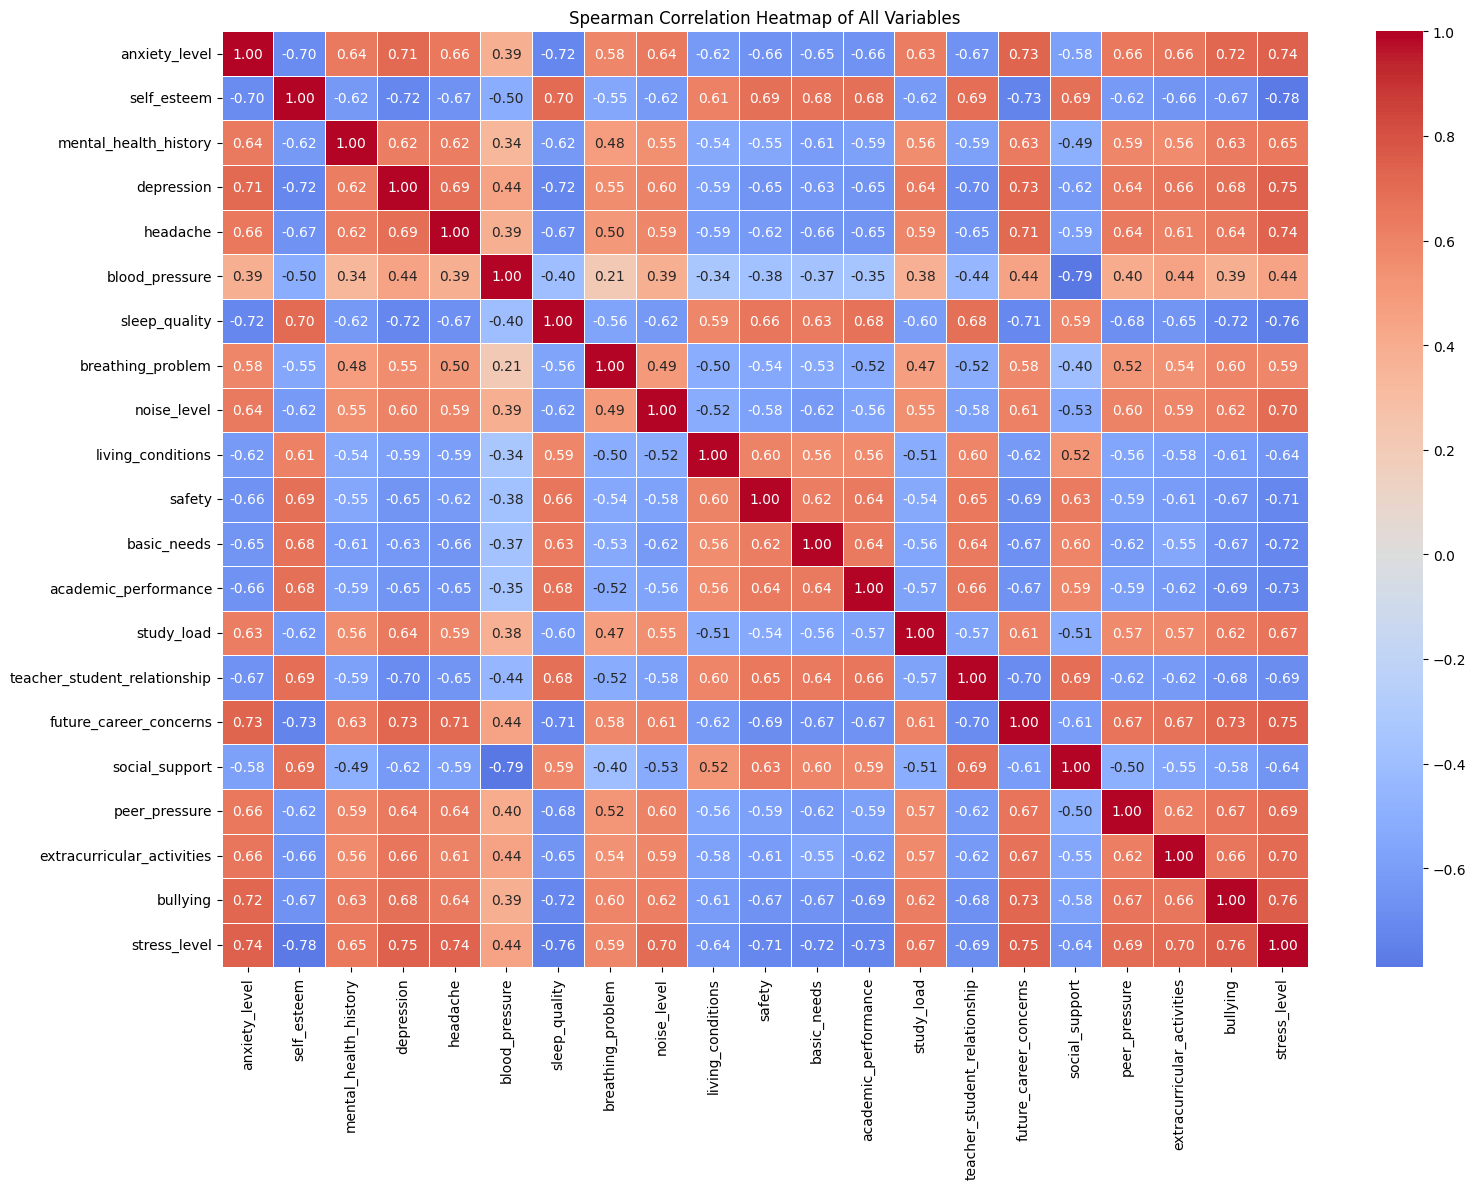

In [16]:
# Generate a Spearman Correlation Heatmap for All Variables

# Calculate Spearman correlations across all dataset columns
correlation_matrix = df.corr(method="spearman")

# Plot the correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation Heatmap of All Variables")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The Spearman correlation heatmap reveals several notable relationships among the dataset variables. `bullying`, `future_career_concerns`, `depression`, `anxiety_level`, and `headache` show strong positive correlations with `stress_level`, while `self_esteem` and `sleep_quality` show strong negative correlations.

Other notable relationships include a positive correlation between `basic_needs` and `academic_performance` (ρ = 0.84), and between `anxiety_level` and `depression` (ρ = 0.70). `social_support` is negatively correlated with both `bullying` and `future_career_concerns`.

Overall, the heatmap highlights interconnected psychological, social, environmental, and academic factors. These are associations, not evidence of causation, and the coding of individual variables should be considered when interpreting the results.

## 6. Discussion and Conclusion

### 6.1 Discussion of Key Findings

In [17]:
# Step 6.1: Summarize the Strongest Associations with Stress Level

stress_correlations = (df.corr(method="spearman")["stress_level"].drop("stress_level")
                       .sort_values(key=abs, ascending=False))

display(stress_correlations.to_frame(name="Spearman Correlation (rho)").round(3))

,Spearman Correlation (rho)
self_esteem,-0.779
sleep_quality,-0.761
bullying,0.760
future_career_concerns,0.754
depression,0.747
anxiety_level,0.742
headache,0.737
academic_performance,-0.728
basic_needs,-0.719
safety,-0.714


### Interpretation

The analysis identified several strong associations with recorded stress levels. Self-esteem (ρ = −0.779) and sleep quality (ρ = −0.761) showed the strongest negative correlations, while bullying (ρ = 0.760) and future career concerns (ρ = 0.754) showed strong positive correlations. Depression, anxiety, and headache also showed strong positive associations.

Academic performance, basic needs, safety, teacher–student relationships, and social support were negatively associated with stress levels. Overall, the findings highlight psychological, social, academic, environmental, and physiological factors associated with recorded student stress. However, correlation does not establish causation, and undocumented variable coding limits some interpretations.

### 6.2 Limitations of the Study

This study has several limitations. The dataset's questionnaire design, variable coding, and method of assigning stress levels are not fully documented. Therefore, the clinical meaning of some variables and the validity of the recorded stress categories cannot be independently confirmed. The observed associations do not establish causation, and the findings may not generalize to all student populations. The unusual pattern between blood-pressure codes and stress levels also warrants further investigation.

### 6.3 Conclusion and Recommendations

This study examined statistical associations between selected psychological, physiological, environmental, academic, and social variables and recorded student stress categories. Using Spearman's rank correlation and hypothesis testing with Benjamini–Hochberg adjustment, the analysis identified statistically significant associations between stress_level and all ten variables included in the hypothesis tests. The correlation heatmap also revealed relationships among several explanatory variables.

These findings are broadly relevant to the student-stress factors discussed by de Filippis and Al Foysal (2024). However, the present analysis focuses on statistical associations and does not establish causal relationships.

Future research should verify the dataset's questionnaire, variable coding, and stress-level classification method. The unusual relationship between blood-pressure codes and recorded stress levels also warrants further investigation. Independent data collection and validation would help establish whether these patterns generalize to other student populations.